# SVT disk hit map

This notebook reads `TrackerEndcapHits` from the simulation ROOT file. First inspect the hit distribution in global z, then enter the z range of one disk and plot its global x-y hit map.

In [3]:
from pathlib import Path

import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
import uproot

#input_file = Path('/global/cfs/cdirs/m3763/pdatta/npsim/sim_two_neigh_rows_full_tracking.root')
#input_file = Path('/global/cfs/cdirs/m3763/pdatta/npsim/sim_two_neigh_rows_onesided_tracking.root')
#input_file = Path('/global/cfs/cdirs/m3763/pdatta/npsim/sim_effi_etascan_10GeV_tracking.root')
#input_file = Path('/global/cfs/cdirs/m3763/pdatta/npsim/sim_uniform_allside_tracking.root')
input_file = Path('../simout/sim_vALL_8n_all_job_0_4.root')
collection = 'TrackerEndcapHits'
tree_name = 'events'

In [4]:
with uproot.open(input_file) as root_file:
    tree = root_file[tree_name]
    x = ak.to_numpy(ak.flatten(tree[f'{collection}.position.x'].array(), axis=None))
    y = ak.to_numpy(ak.flatten(tree[f'{collection}.position.y'].array(), axis=None))
    z = ak.to_numpy(ak.flatten(tree[f'{collection}.position.z'].array(), axis=None))

print(f'Loaded {len(x):,} hits')
print(f'Global z range: {z.min():.1f} to {z.max():.1f} mm')

Loaded 121,305 hits
Global z range: -1023.6 to 1203.6 mm


## 1. Find the disk in z

Each group of peaks corresponds to one physical SVT disk. Zoom the plot if necessary, then enter limits around one group in the next cell. The several nearby peaks within a group come from the corrugated module surfaces.

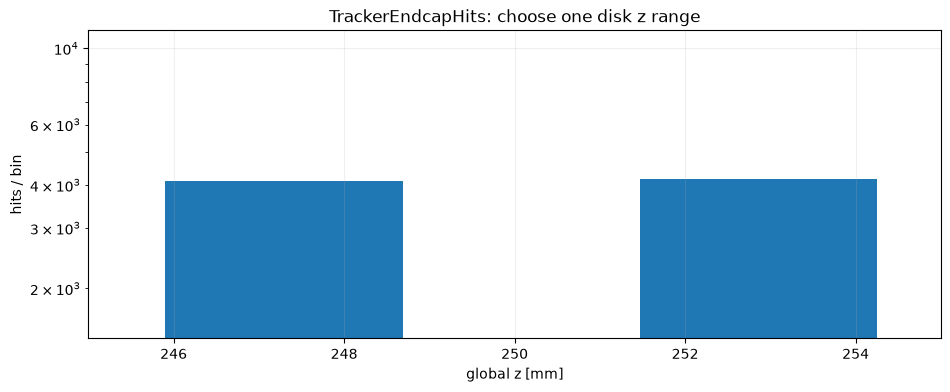

In [9]:
plt.figure(figsize=(11, 4))
plt.hist(z, bins=800)
plt.xlim(245,255)
plt.yscale('log')
plt.xlabel('global z [mm]')
plt.ylabel('hits / bin')
plt.title('TrackerEndcapHits: choose one disk z range')
plt.grid(alpha=0.2)
plt.show()

## 2. Select one disk

Edit `z_min_mm` and `z_max_mm` to enclose all nearby peaks belonging to the disk you want.

In [10]:
# EDIT THESE TWO VALUES after inspecting the z histogram above.
z_min_mm = 245
z_max_mm = 255

disk_hits = (z >= z_min_mm) & (z <= z_max_mm)
print(f'Selected {disk_hits.sum():,} hits in [{z_min_mm}, {z_max_mm}] mm')

Selected 8,283 hits in [245, 255] mm


## 3. Plot the disk hit map

Hits should follow the sensitive silicon regions. Unilluminated sensitive regions may remain empty if the simulation sample contains no tracks through them.

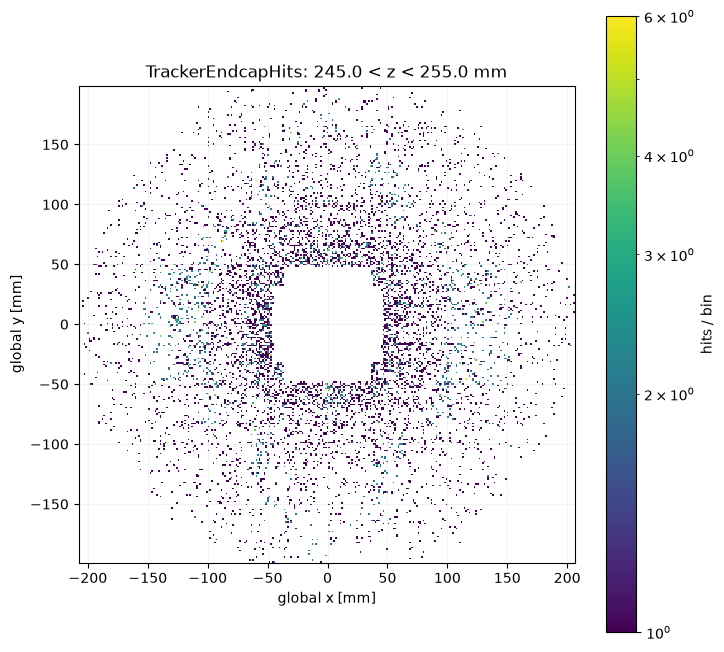

In [11]:
if disk_hits.sum() == 0:
    raise ValueError('No hits selected. Check the z limits in the previous cell.')

fig, ax = plt.subplots(figsize=(8, 8))
hit_map = ax.hist2d(x[disk_hits], y[disk_hits], bins=300, cmin=1, norm='log')
hit_map = ax.hist2d(
    x[disk_hits],
    y[disk_hits],
    bins=300,
    #range=[[-110, -60], [-12, 12]],  # [[xmin, xmax], [ymin, ymax]] in mm
    #bins=[500, 300],
    #range=[[50, 250], [-80, 80]],    
    cmin=1,
    norm="log",
)
# x_range = (-108.6, -86.7)
# y_range = (-10.0, 10.0)

# hit_map = ax.hist2d(
#     x[disk_hits],
#     y[disk_hits],
#     bins=[
#         int((x_range[1] - x_range[0]) / 0.02),
#         int((y_range[1] - y_range[0]) / 0.02),
#     ],
#     range=[x_range, y_range],
#     cmin=1,
#     norm="log",
# )
fig.colorbar(hit_map[3], ax=ax, label='hits / bin')
ax.set_xlabel('global x [mm]')
ax.set_ylabel('global y [mm]')
ax.set_title(f'{collection}: {z_min_mm:.1f} < z < {z_max_mm:.1f} mm')
ax.set_aspect('equal')
ax.grid(alpha=0.15)
plt.show()

fig.savefig(f'hit_map_{collection}_{z_min_mm:.0f}_{z_max_mm:.0f}.png', dpi=300)

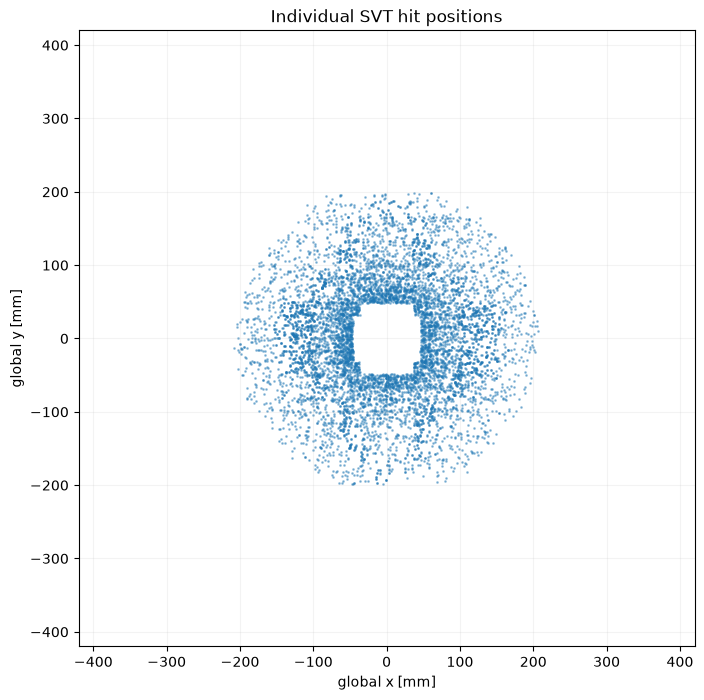

In [12]:
plt.figure(figsize=(8, 8))
plt.scatter(x[disk_hits], y[disk_hits], s=1, alpha=0.4)
plt.xlim(-420, 420)
plt.ylim(-420, 420)
plt.xlabel('global x [mm]')
plt.ylabel('global y [mm]')
plt.title('Individual SVT hit positions')
plt.gca().set_aspect('equal')
plt.grid(alpha=0.15)
plt.show()

### Optional: inspect individual hit positions

The scatter view can make boundaries and gaps between sensitive regions easier to recognize.

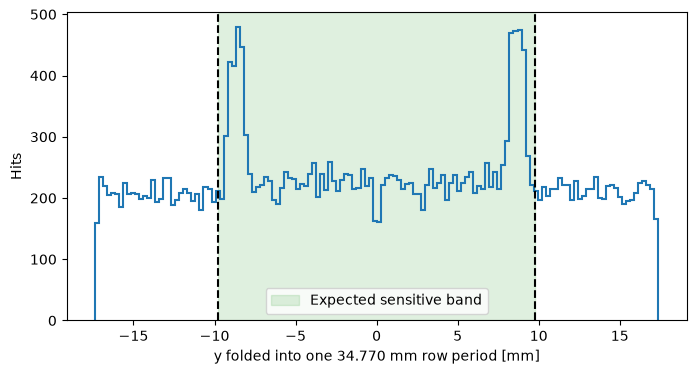

In [72]:
row_pitch = 34.770
active_half_width = 19.564 / 2

selected_y = y[disk_hits]

row_coordinate = (
    (selected_y + row_pitch / 2) % row_pitch
) - row_pitch / 2

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    row_coordinate,
    bins=140,
    range=(-row_pitch / 2, row_pitch / 2),
    histtype="step",
    linewidth=1.5,
)

ax.axvspan(
    -active_half_width,
    active_half_width,
    color="tab:green",
    alpha=0.15,
    label="Expected sensitive band",
)

ax.axvline(-active_half_width, color="black", linestyle="--")
ax.axvline(active_half_width, color="black", linestyle="--")

ax.set_xlabel("y folded into one 34.770 mm row period [mm]")
ax.set_ylabel("Hits")
ax.legend()
plt.show()

fig.savefig(f'see_gap.png', dpi=300)

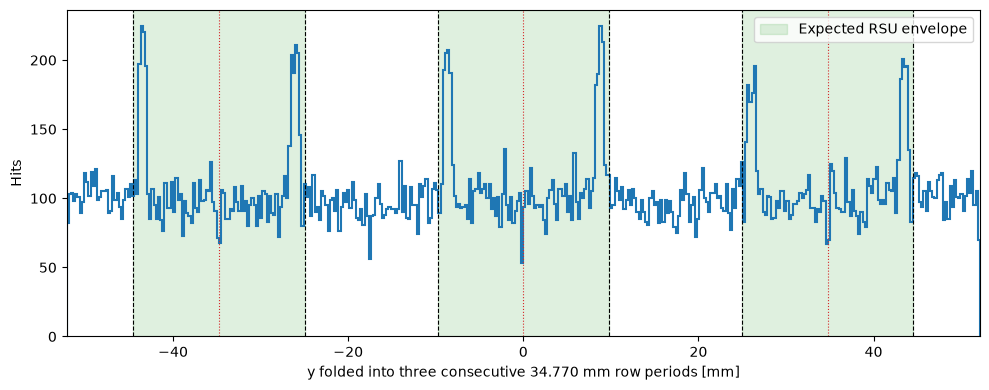

In [50]:
row_pitch = 34.770
rsu_half_width = 19.564 / 2
three_row_period = 3 * row_pitch

selected_y = y[disk_hits]

# Fold hits into a window centered on three consecutive rows.
three_row_coordinate = (
    (selected_y + three_row_period / 2) % three_row_period
) - three_row_period / 2

fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(
    three_row_coordinate,
    bins=420,  # Preserves the original 140 bins per row period
    range=(-three_row_period / 2, three_row_period / 2),
    histtype="step",
    linewidth=1.5,
)

row_centers = [-row_pitch, 0.0, row_pitch]

for index, row_center in enumerate(row_centers):
    active_min = row_center - rsu_half_width
    active_max = row_center + rsu_half_width

    ax.axvspan(
        active_min,
        active_max,
        color="tab:green",
        alpha=0.15,
        label="Expected RSU envelope" if index == 0 else None,
    )

    ax.axvline(active_min, color="black", linestyle="--", linewidth=0.8)
    ax.axvline(active_max, color="black", linestyle="--", linewidth=0.8)
    ax.axvline(row_center, color="tab:red", linestyle=":", linewidth=0.8)

ax.set_xlim(-three_row_period / 2, three_row_period / 2)
ax.set_xlabel("y folded into three consecutive 34.770 mm row periods [mm]")
ax.set_ylabel("Hits")
ax.legend()
fig.tight_layout()

fig.savefig("see_three_rows.png", dpi=300)
plt.show()

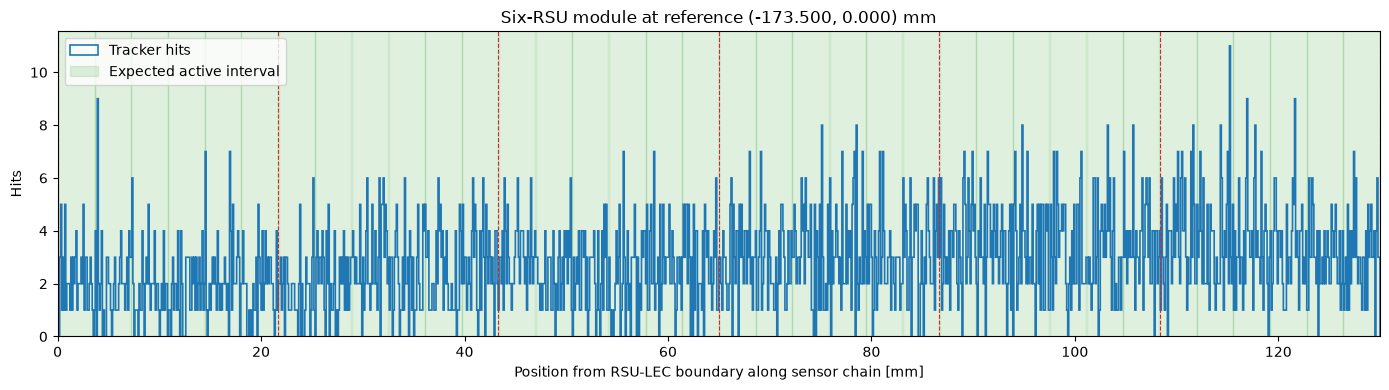

In [51]:
# Inputs for one module from the placement CSV.
disk_z_mm = 249.865
module_ref_x_mm = -173.500
module_ref_y_mm = 0.0
handedness = "left"

# Implemented RSU dimensions in mm.
rsu_pitch = 21.666
number_of_rsus = 6
rsu_chain_length = number_of_rsus * rsu_pitch

rsu_width = 19.564
rsu_half_width = rsu_width / 2

backbone_width = 0.060
power_switch_width = 0.020
half_rsu_length = rsu_pitch / 2

tile_x_width = (
    half_rsu_length
    - backbone_width
    - 3 * power_switch_width
) / 3

# Select the disk and the y envelope of the chosen module.
disk_z_tolerance = 10.0

selected_module = (
    (np.abs(z - disk_z_mm) < disk_z_tolerance)
    & (np.abs(y - module_ref_y_mm) < rsu_half_width)
)

# Define a handed local coordinate measured from the RSU-LEC boundary.
# It always increases from the boundary through the six-RSU sensor chain.
if handedness == "left":
    module_x = x - module_ref_x_mm
elif handedness == "right":
    module_x = module_ref_x_mm - x
else:
    raise ValueError("handedness must be 'left' or 'right'")

selected_module &= (
    (module_x >= 0.0)
    & (module_x <= rsu_chain_length)
)

fig, ax = plt.subplots(figsize=(14, 4))

ax.hist(
    module_x[selected_module],
    bins=1300,  # Approximately 0.1 mm/bin
    range=(0.0, rsu_chain_length),
    histtype="step",
    linewidth=1.2,
    color="tab:blue",
    label="Tracker hits",
)

# Draw the expected active x intervals.
first_active_label = True

for rsu_index in range(number_of_rsus):
    rsu_start = rsu_index * rsu_pitch

    for x_half in range(2):
        half_start = rsu_start + x_half * half_rsu_length

        for tile_index in range(3):
            active_start = (
                half_start
                + backbone_width
                + tile_index * (tile_x_width + power_switch_width)
            )
            active_end = active_start + tile_x_width

            ax.axvspan(
                active_start,
                active_end,
                color="tab:green",
                alpha=0.15,
                label="Expected active interval"
                if first_active_label else None,
            )
            first_active_label = False

    # Mark the RSU boundaries.
    ax.axvline(
        rsu_start,
        color="tab:red",
        linestyle="--",
        linewidth=0.8,
    )

ax.axvline(
    rsu_chain_length,
    color="tab:red",
    linestyle="--",
    linewidth=0.8,
)

ax.set_xlim(0.0, rsu_chain_length)
ax.set_xlabel("Position from RSU-LEC boundary along sensor chain [mm]")
ax.set_ylabel("Hits")
ax.set_title(
    f"Six-RSU module at reference "
    f"({module_ref_x_mm:.3f}, {module_ref_y_mm:.3f}) mm"
)
ax.legend()
fig.tight_layout()

fig.savefig("one_eic_las_x_intervals.png", dpi=300)
plt.show()